# 09_dryad: Dryad

Dryad API search (38 Toxoplasma records, almost all animal or laboratory); files from the Zenodo mirror.

**Same protocol for every dataset** (`datasets/common/protocol.py`): label = Toxoplasma IgG positive; every column that measures Toxoplasma itself (IgM, avidity, titre, OD, PCR, other kits) and identifiers are removed; logistic regression, random forest and XGBoost; ROC-AUC from 5-fold x 3 repeated stratified cross-validation with preprocessing inside the folds. Datasets with fewer than 20 positives or 20 negatives are catalogued but not evaluated.

**Sections:** setup → helpers → one section per dataset (where it comes from, how the label is coded, what is removed) → build and evaluate → chart. Outputs are written to `raw/`, `processed/`, `results.csv`, `DATASETS.md`.

In [1]:
# Setup: run from the repository root and load the shared protocol (datasets/common/*.ipynb)
import os, sys, warnings
os.environ['PYTHONWARNINGS'] = 'ignore'; warnings.filterwarnings('ignore')
while not os.path.isdir('datasets') and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir('..')
sys.path.insert(0, 'scripts')          # curated loaders: scripts/external_datasets.py, us_datasets.py, europe_datasets.py
%run -i datasets/common/protocol.ipynb
%run -i datasets/common/folder_tools.ipynb
import pandas as pd
pd.set_option('display.max_colwidth', 60); pd.set_option('display.width', 200)
HERE = 'datasets/09_dryad'
print('working directory:', os.getcwd())

working directory: /home/claude/toxo


**Notes on this source.** Dryad (datadryad.org): curated research data. Files were downloaded from Dryad's Zenodo mirror (identical files).
Searched 38 Toxoplasma records; most are animal / laboratory studies. Human, individual-level ones are below.

## Helpers (curated loaders and source-specific functions)

In [2]:
L = 'repo_supp/dryad/'

## Datasets

Each cell adds one dataset to `CONFIG`: `source` = where the raw file comes from, `label` / `pos` / `neg` = how the Toxoplasma IgG result is coded, `drop` = extra columns removed (leakage, identifiers, outcomes), `loader` = a hand-written loader in `scripts/` for datasets curated earlier.

In [3]:
CONFIG = []

### usa_students_risky_business

**Risky business: Toxoplasma infection and entrepreneurship behaviours (students)**  
USA · University students, saliva IgG test · DOI/ID: `10.5061/dryad.gd19rr3`

Only 5 inputs: business major, sex, GPA and two career-interest items.

In [4]:
CONFIG.append(dict(key='usa_students_risky_business', title='Risky business: Toxoplasma infection and entrepreneurship behaviours (students)',
     doi='10.5061/dryad.gd19rr3', setting='University students, saliva IgG test', country='USA',
     source=('local', L + '10.5061_dryad.gd19rr3/ClassData_dryad.csv'), file='ClassData_dryad.csv',
     label='Tg_status', pos=['positive'], neg=['negative'],
     note='Only 5 inputs: business major, sex, GPA and two career-interest items.'))

### usa_entrepreneur_event

**Risky business: Toxoplasma status of professionals at entrepreneurship events**  
USA · Professionals attending entrepreneurship events · DOI/ID: `10.5061/dryad.gd19rr3`

18 positives: below the 20-case minimum, catalogued only.

In [5]:
CONFIG.append(dict(key='usa_entrepreneur_event', title='Risky business: Toxoplasma status of professionals at entrepreneurship events',
     doi='10.5061/dryad.gd19rr3', setting='Professionals attending entrepreneurship events', country='USA',
     source=('local', L + '10.5061_dryad.gd19rr3/entrep_dryad.csv'), file='entrep_dryad.csv',
     label='Tg_status', pos=['1'], neg=['0'], note='18 positives: below the 20-case minimum, catalogued only.'))

## Build and evaluate

Downloads (or copies) each raw file into `raw/`, builds `processed/<dataset>.csv`, removes leakage columns, then runs logistic regression, random forest and XGBoost with 5-fold x 3 cross-validation.

In [6]:
res = run(HERE, CONFIG)

usa_students_risky_business        n=  1293 pos=  325 feats=  3 best AUC=0.571 (LogReg)
usa_entrepreneur_event             n=   197 pos=   18 feats=  2 best AUC=nan (not evaluated (fewer than 20 positives or negatives))


In [7]:
cols = ['dataset', 'country', 'n', 'positives', 'prevalence', 'n_features', 'LogReg_auc', 'RandomForest_auc', 'XGBoost_auc',
        'best_auc', 'best_model']
res[[c for c in cols if c in res]]

,dataset,country,n,positives,prevalence,n_features,LogReg_auc,RandomForest_auc,XGBoost_auc,best_auc,best_model
0,usa_students_risky_business,USA,1293,325,0.251,3,0.571,0.508,0.534,0.571,LogReg
1,usa_entrepreneur_event,USA,197,18,0.091,2,NaN,NaN,NaN,NaN,not evaluated (fewer than 20 positives or negatives)


## Chart

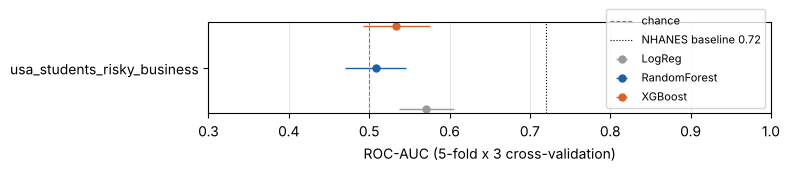

In [8]:
# ROC-AUC per dataset and model (error bars: SD over the 15 CV folds)
import matplotlib.pyplot as plt
r = res[res.best_auc.notna()].sort_values('best_auc')
if len(r):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(r) + 1.2))
    for k, (m, c) in enumerate([('LogReg', '#9a9a9a'), ('RandomForest', '#1f5fa8'), ('XGBoost', '#d9622b')]):
        ax.errorbar(r[f'{m}_auc'], [i + (k - 1) * 0.18 for i in range(len(r))], xerr=r[f'{m}_sd'], fmt='o', ms=5,
                    color=c, label=m, elinewidth=1)
    ax.axvline(0.5, ls='--', color='grey', lw=0.8, label='chance')
    ax.axvline(0.72, ls=':', color='black', lw=0.8, label='NHANES baseline 0.72')
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r.dataset)
    ax.set_xlabel('ROC-AUC (5-fold x 3 cross-validation)'); ax.set_xlim(0.3, 1.0)
    ax.legend(loc='lower right', fontsize=8); ax.grid(axis='x', alpha=0.3)
    plt.tight_layout(); plt.show()

## What was removed as leakage, and the inputs used

In [9]:
res[['dataset', 'removed_as_leakage', 'features']]

,dataset,removed_as_leakage,features
0,usa_students_risky_business,,"business_major, sex, gpa"
1,usa_entrepreneur_event,,"entrepreneur, sex"
